# 08 - Make the final Catalogue

From the calibrated frame extract the photometry of the stars using Sextractor<br>
Apply light correction based on the results of the notebook 7.b<br>
Save the final catalogue combining Pycavi and Gaia photometries<br>

Done:<br>
* Sextractor running over the calibrated frame
* Read the catalogue (fits table)
* Read the Gaia catalogue
* Cross match the catalogues
* Create the final catalogue
* Create a merged catalogue of the sextractor images
* Clean the merged sextractor catalogue before comparing with Gaia
* First crossmatch the sextractor catalogues, then cross with Gaia
* Pack the code into the cell
* Add the zero point depending on the filter
* Validate r filter against SkyMapper
* Modify the zp cal notebook to save additional Gaia parameters
* Save the Gaia query as a raw query, create the clean versions as a different files, or add an additional column that defines if the source in each row is used in the clean version.
* Get the zp from the frame itself

ToDo:<br>
* Add the illumination correction for kriggin and chebyshev. Each illumination creates a different catalogue
* order a bit the output catalogue. First three columns must be index, raj2000 and dej2000 from pycavi.
* Modify the papi sextractor function so redo sextractor False efectively do not run sextractor again.
* Validate NB filter against VPHAS

Notes:<br>
* Modified the papi_sextractor to allows the default parameter file to incorporated the position of the stars (XY_IMAGE, ALPHA/DELTA_J2000), as well as the Petro flux and mag.
* Petro mags shows the slopeless results when comparing Sextractor and Gaia mags.
* The zero points for photometry depend on the filter only: 21.40 for r_SDSS and 21.50 for NB in AB system.
* The merged catalogue includes the r_SDSS and NB filters, together with the Gaia data.
* The pycavi ra and dec were mean combined

In [1]:
import os
import sys
import glob
import logging
from datetime import datetime

import pandas as pd
from astropy.io import fits
from astropy.table import Table

sys.path.append(os.path.join(os.path.abspath(''), '..')) # to be removed in production
from pycavi import pycavi_tools, pycavi_astromatic_tools
from pycavi.pycavi_zpcal import get_files_dict
from pycavi.pycavi_catalogue import getheaderfromframe, load_catalogue, crossmatch_catalogues, clean_merged_catalogue
from pycavi.pycavi_catalogue import apply_kriggin_illumination_correction, create_catalogue_checkplots
from pycavi.pycavi_catalogue import crossmatch_against_SkyMapper

This will be executed when the package is imported.
"Important:  Gaia archive will be intermittently unavailable due to scheduled maintenance on 10-12-2024 from 08:00 to 10:00 (CET)"


In [2]:
# set the directory folders
config_dir = os.getcwd()+'/../config/'
config = pycavi_tools.read_pycavi_config(config_dir)

observatory = config['Provenance']['observatory'] # Needed for the atmospheric extinction curve
project_dir = config['Directories']['project_dir']
reduced_std_dir = config['Directories']['reduced_std_dir']
reduced_science_dir = config['Directories']['reduced_science_dir']  
log_dir = config['Directories']['project_logs_dir']

log_file_swarp = log_dir + "/pymeffpp_zpcal_check.log"
logging.basicConfig(level=logging.INFO,
                    format="%(asctime)s:%(levelname)s:%(message)s",
                    handlers=[
                              logging.FileHandler(log_file_swarp),
                              logging.StreamHandler()])
logging.getLogger().setLevel(logging.INFO)

# At this point it is believed that the data reduction process
# should be closely monitored, so we calibrate target/filter sets,
# that is each data partition, one by one.
#
filters = []
reject_observations = []
dir_name = config['Directories']['cal_dir_name']
zpcal_dict = get_files_dict(reduced_std_dir, reduced_science_dir, dir_name, filters, reject_observations)

zpcal_dict = dict(sorted(zpcal_dict.items()))

i = 0
for key in zpcal_dict.keys():
    for j in range(len(zpcal_dict[key])):
        logging.info('index: {} -- file: {} : {}'.format(i, j, zpcal_dict[key][j]))
    i += 1
    

2024-12-06 18:44:04,150:INFO:index: 0 -- file: 0 : /home/lceledon/Investigacion/OmegaCam/Work_dir/science/HL_Aqr/Calibration_dir/HL_Aqr_r_SDSS.coadd.fits
2024-12-06 18:44:04,151:INFO:index: 0 -- file: 1 : /home/lceledon/Investigacion/OmegaCam/Work_dir/science/HL_Aqr/Calibration_dir/HL_Aqr_NB_659.coadd.fits


In [9]:
redo_sextractor = True
idx_selected = [0]    # Keep empty to check all science objects

i = 0
for science in zpcal_dict.keys():

    if not (i in idx_selected or not idx_selected):
        continue
    
    merged_table = None  # as it creates the sextractor catalogues, starts inmediately to do the crossmatch with the 
                         # previous catalogue
    
    list_of_filters = []
    for i in range(len(zpcal_dict[science])):
        
        target = zpcal_dict[science][i]
        sextractor_dir_path = "/".join(target.split("/")[:-2])+'/'+config['Directories']['sex_dir_name']
        try:
            logging.info("Atempting to create the Sextractor_dir folder: {}".format(reduced_science_dir+target_name))
            os.mkdir(sextractor_dir_path)
            logging.info("Folder created")
        except:
            logging.info("Folder already exists")
        
        # check the filter and object of the target
        target_filter = getheaderfromframe(target, 'FILTER')
        list_of_filters.append(target_filter)
        target_name = getheaderfromframe(target, 'OBJECT').replace(' ', '_')
        
        # run sextractor on frame
        ready_to_sextract = pycavi_astromatic_tools.prepare_to_sextract(target, redo_sextractor)
    
        # we tune some parameters for sextractr
        special_pars = {}
        special_pars["SATUR_KEY"] = "SATLEVEL"   # FITS keyword giving saturation value
        special_pars["DETECT_MINAREA"] = 5       # minimum number of pixels above threshold
        special_pars["DETECT_MAXAREA"] = 0       # maximun number of pixels above threshold
        special_pars["DETECT_THRESH"] = 5.0      # <sigmas> or <threshold>,<ZP> in mag.arcsec-2
        special_pars["ANALYSIS_THRESH"] = 5.0    # <sigmas> or <threshold>,<ZP> in mag.arcsec-2
        special_pars["SEEING_FWHM"] = 1.2        # stellar FWHM in arcsec (we give here typical not so good value)
        special_pars["PHOT_APERTURES"] = 5       # MAG_APER aperture diameter(s) in pixels
        special_pars["MAG_ZEROPOINT"] = getheaderfromframe(target, 'MAGZP')    # magnitude zero-point from the frames header
        special_pars["GAIN"] =  1.0              # detector gain in e-/ADU - if DN in e/s then 1.0
        special_pars["MEMORY_OBJSTACK"] = 6000   # number of objects in stack [3000]
        special_pars["MEMORY_PIXSTACK"] = 600000 # number of pixels in stack [300000]
        special_pars['CHECKIMAGE_TYPE'] = 'BACKGROUND'
        special_pars['CHECKIMAGE_NAME'] = 'check_{}.fits'.format(target_filter)
        special_pars['BACK_SIZE'] = 128
    
        # the measurement parameters to get during the extraction. They will be present in the final catalogue
        # the mandatory parameter list is required to do the cross match between catalogues
        # the optionally parameter list includes all the rest of desired parameters to be extracted
        mandatory_parameter_list = ['NUMBER', 'ALPHA_J2000', 'DELTA_J2000']
        optionally_parameter_list = ['MAG_ISO', 'MAGERR_ISO', 'FLUX_PETRO','FLUXERR_PETRO','MAG_PETRO', 'MAGERR_PETRO', 'MAG_AUTO', 'MAGERR_AUTO', 'MAG_BEST', 'MAGERR_BEST', 
                                     'X_IMAGE', 'Y_IMAGE', 'A_IMAGE', 'B_IMAGE', 'THETA_IMAGE', 'FLAGS']
        parameter_list = mandatory_parameter_list + optionally_parameter_list
        special_pars['PARAMETERS_LIST'] = parameter_list
        
        if ready_to_sextract:
            if not os.path.isfile(target[:-5]+'.cat') or redo_sextractor:
                pycavi_astromatic_tools.run_sextractor_on_target(target, sextractor_dir_path, special_pars)
        
        # sextractor is done
        logging.info("SExtractor finished on image {}".format(target.split("/")[-1]))
        
        # start the cross matching process
        # add the filter tag to each column in the table to differentiate from the other data
        if merged_table is None:
            logging.info('Creating catalogue for filter '+target_filter)
            merged_table = load_catalogue(target[:-5]+'.cat')
            # add the filter tag to each column in the catalogue to make them unique
            for col in merged_table.colnames:
                merged_table.rename_column(col, col+'_'+target_filter)
            # save the filter tag that will identify the merged catalogue from here on
            merged_filter = target_filter
        else:
            single_table = load_catalogue(target[:-5]+'.cat')
            # update the column names by adding the filter tag
            for col in single_table.colnames:
                single_table.rename_column(col, col+'_'+target_filter)
            # defines the ra and dec tags for the single catalogue
            radec_tag_single = ['ALPHA_J2000_'+target_filter, 'DELTA_J2000_'+target_filter]
            radec_tag_merged = ['ALPHA_J2000_'+merged_filter, 'DELTA_J2000_'+merged_filter]
            logging.info('Crossmatching {} and {} catalogues...'.format(merged_filter, target_filter))
            merged_table = crossmatch_catalogues(merged_table, single_table, 
                                                 radec_tag_1=radec_tag_merged, radec_tag_2=radec_tag_single)
    
    # Clean merged table
    
    savename = '/'.join(target.split('/')[:-1]) +'/'+ target_name + '_merged_catalogue.fits'
    clean_table = clean_merged_catalogue(merged_table)
    
    # cross match with Gaia and save
    logging.info('Reading Gaia query...')
    target_split = target.split('/')
    query_gaia = '/'.join(target.split('/')[:-1])+'/gaia3_qry_{}_raw.csv'.format(target_name)
    gaia_catalogue = pd.read_csv(query_gaia)
    gaia_catalogue = Table.from_pandas(gaia_catalogue)
    
    for col in gaia_catalogue.colnames:
        gaia_catalogue.rename_column(col, col+'_gaia')
    
    logging.info('Crossmatching Pycavi and Gaia catalogues...')
    merged_clean_gaia = crossmatch_catalogues(clean_table, gaia_catalogue, 
                                              radec_tag_1=['raj2000', 'dej2000'], 
                                              radec_tag_2=['raj2000_gaia', 'dej2000_gaia'])
    
    # Convert the Astropy Table to a Table HDU
    table_hdu = fits.BinTableHDU(merged_clean_gaia)
    
    logging.info('Adding basic headers to the catalogue...')
    # Create a Primary HDU with custom headers
    now = datetime.now()
    formatted_date = now.strftime("%Y-%m-%dT%H:%S.%f")[:-3] # ISO 8601 truncated to millisecond
    
    primary_hdu = fits.PrimaryHDU()
    primary_hdu.header['DATE'] = (formatted_date, 'Date of creation of this catalogue')
    primary_hdu.header['ORIGFILE'] = "SPDP."+formatted_date+".fits"
    primary_hdu.header['TELESCOP'] = ('ESO-VST', 'ESO Telescope Designation')
    primary_hdu.header['INSTRUME'] = ('OMEGACAM', 'Instrument name')
    for i in range(len(list_of_filters)):
        primary_hdu.header['FILTER{:02d}'.format(i)] = (list_of_filters[i], 'Name of filter used for catalogue') 
    primary_hdu.header['OBJECT'] = (target_name.replace('_',' '), 'Name of the pointing target')
    primary_hdu.header['RA'] = (getheaderfromframe(target, 'RA'), 'Tile center RA J2000')
    primary_hdu.header['DEC'] = (getheaderfromframe(target, 'DEC'), 'Tile center Dec J2000')
    
    # Combine Primary HDU and Table HDU into an HDUList
    hdul = fits.HDUList([primary_hdu, table_hdu])
    
    # Write to a FITS file
    logging.info('Saving merged catalogue as '+savename)
    hdul.writeto(savename, overwrite=True)

    # update the counter
    i += 1

logging.info("-------Done-------")

2024-11-28 16:11:39,928:INFO:Atempting to create the Sextractor_dir folder: /home/lceledon/Investigacion/OmegaCam/Work_dir/science/HL_Aqr
2024-11-28 16:11:39,929:INFO:Folder already exists
2024-11-28 16:11:39,933:INFO:Running Sextractor on image HL_Aqr_r_SDSS.coadd.fits
2024-11-28 16:11:39,935:INFO:Moving to target's directory: /home/lceledon/Investigacion/OmegaCam/Work_dir/science/HL_Aqr/Calibration_dir
2024-11-28 16:11:39,935:INFO:sextractor.config[SATUR_KEY] = SATLEVEL
2024-11-28 16:11:39,936:INFO:sextractor.config[DETECT_MINAREA] = 5
2024-11-28 16:11:39,936:INFO:sextractor.config[DETECT_MAXAREA] = 0
2024-11-28 16:11:39,936:INFO:sextractor.config[DETECT_THRESH] = 5.0
2024-11-28 16:11:39,937:INFO:sextractor.config[ANALYSIS_THRESH] = 5.0
2024-11-28 16:11:39,937:INFO:sextractor.config[SEEING_FWHM] = 1.2
2024-11-28 16:11:39,938:INFO:sextractor.config[PHOT_APERTURES] = 5
2024-11-28 16:11:39,938:INFO:sextractor.config[MAG_ZEROPOINT] = -21.374
2024-11-28 16:11:39,938:INFO:sextractor.config

sextractor_base_dir: /home/lceledon/Investigacion/OmegaCam/Work_dir/science/HL_Aqr/Calibration_dir


2024-11-28 16:11:54,599:INFO:SExtractor finished on image HL_Aqr_r_SDSS.coadd.fits
2024-11-28 16:11:54,600:INFO:Creating catalogue for filter r_SDSS
2024-11-28 16:11:54,615:INFO:Atempting to create the Sextractor_dir folder: /home/lceledon/Investigacion/OmegaCam/Work_dir/science/HL_Aqr
2024-11-28 16:11:54,615:INFO:Folder already exists
2024-11-28 16:11:54,618:INFO:Running Sextractor on image HL_Aqr_NB_659.coadd.fits
2024-11-28 16:11:54,620:INFO:Moving to target's directory: /home/lceledon/Investigacion/OmegaCam/Work_dir/science/HL_Aqr/Calibration_dir
2024-11-28 16:11:54,621:INFO:sextractor.config[SATUR_KEY] = SATLEVEL
2024-11-28 16:11:54,621:INFO:sextractor.config[DETECT_MINAREA] = 5
2024-11-28 16:11:54,621:INFO:sextractor.config[DETECT_MAXAREA] = 0
2024-11-28 16:11:54,622:INFO:sextractor.config[DETECT_THRESH] = 5.0
2024-11-28 16:11:54,622:INFO:sextractor.config[ANALYSIS_THRESH] = 5.0
2024-11-28 16:11:54,623:INFO:sextractor.config[SEEING_FWHM] = 1.2
2024-11-28 16:11:54,623:INFO:sextrac

py-sextractor.cat --> HL_Aqr_r_SDSS.coadd.cat
sextractor_base_dir: /home/lceledon/Investigacion/OmegaCam/Work_dir/science/HL_Aqr/Calibration_dir


2024-11-28 16:12:10,070:INFO:SExtractor finished on image HL_Aqr_NB_659.coadd.fits
2024-11-28 16:12:10,087:INFO:Crossmatching r_SDSS and NB_659 catalogues...
2024-11-28 16:12:10,107:INFO:Reading Gaia query...
2024-11-28 16:12:10,188:INFO:Crossmatching Pycavi and Gaia catalogues...
2024-11-28 16:12:10,252:INFO:Adding basic headers to the catalogue...
2024-11-28 16:12:10,257:INFO:Saving merged catalogue as /home/lceledon/Investigacion/OmegaCam/Work_dir/science/HL_Aqr/Calibration_dir/HL_Aqr_merged_catalogue.fits


py-sextractor.cat --> HL_Aqr_NB_659.coadd.cat


2024-11-28 16:12:10,273:INFO:-------Done-------


## Illumination correction

The illumination correction is applied to the merged catalogue. For the moment it only consider the kriggin files.

In [4]:
i = 0
for science in zpcal_dict.keys():

    kriging_files = sorted(glob.glob(science+'/*/*.kriging.fits'))
    for j in range(len(kriging_files)):
        logging.info("index: {} -- file: {} : {}".format(i, j, kriging_files[i]))
    i+=1

2024-11-21 18:45:03,446:INFO:index: 0 -- file: 0 : /home/lceledon/Investigacion/OmegaCam/Work_dir/science/FO_Aqr/Calibration_dir/FO_Aqr_NB_659.coadd_krige_gaussian_nugget_fit_01.kriging.fits
2024-11-21 18:45:03,447:INFO:index: 0 -- file: 1 : /home/lceledon/Investigacion/OmegaCam/Work_dir/science/FO_Aqr/Calibration_dir/FO_Aqr_NB_659.coadd_krige_gaussian_nugget_fit_01.kriging.fits


In [5]:
# specify the catalogues to use
idx_selected = [0]
i = 0
for science in zpcal_dict.keys():

    if not (i in idx_selected or not idx_selected):
        continue

    catalogue = glob.glob(science+'/*/*merged_catalogue.fits')[0]
    logging.info('Applying illumination correction to catalogue {}'.format(catalogue))
    kriging_files = sorted(glob.glob(science+'/*/*.kriging.fits'))
    for j in range(len(kriging_files)):
        logging.info('Applying Kriging illumination correction file: {}'.format(kriging_files[j]))

        corr = apply_kriggin_illumination_correction(kriging_files[j], catalogue)
    i+=1

2024-11-21 18:45:06,395:INFO:Applying illumination correction to catalogue /home/lceledon/Investigacion/OmegaCam/Work_dir/science/FO_Aqr/Calibration_dir/FO_Aqr_merged_catalogue.fits
2024-11-21 18:45:06,396:INFO:Applying Kriging illumination correction file: /home/lceledon/Investigacion/OmegaCam/Work_dir/science/FO_Aqr/Calibration_dir/FO_Aqr_NB_659.coadd_krige_gaussian_nugget_fit_01.kriging.fits
2024-11-21 18:45:06,491:INFO:Applying Kriging illumination correction file: /home/lceledon/Investigacion/OmegaCam/Work_dir/science/FO_Aqr/Calibration_dir/FO_Aqr_r_SDSS.coadd_krige_gaussian_nugget_fit_01.kriging.fits


## Validation against SkyMapper

In [3]:
i = 0
catalogue_files = sorted(glob.glob(project_dir+'science/*/Calibration_dir/*merged_catalogue.fits'))
for catalogue in catalogue_files:
    logging.info("index: {} -- file: {}".format(i, catalogue))
    i += 1

2024-12-06 18:44:11,325:INFO:index: 0 -- file: /home/lceledon/Investigacion/OmegaCam/Work_dir/science/BD_Pav/Calibration_dir/BD_Pav_merged_catalogue.fits
2024-12-06 18:44:11,326:INFO:index: 1 -- file: /home/lceledon/Investigacion/OmegaCam/Work_dir/science/BX_Pup/Calibration_dir/BX_Pup_merged_catalogue.fits
2024-12-06 18:44:11,327:INFO:index: 2 -- file: /home/lceledon/Investigacion/OmegaCam/Work_dir/science/CN_Ori/Calibration_dir/CN_Ori_merged_catalogue.fits
2024-12-06 18:44:11,328:INFO:index: 3 -- file: /home/lceledon/Investigacion/OmegaCam/Work_dir/science/CP_Pup/Calibration_dir/CP_Pup_merged_catalogue.fits
2024-12-06 18:44:11,328:INFO:index: 4 -- file: /home/lceledon/Investigacion/OmegaCam/Work_dir/science/CZ_Aql/Calibration_dir/CZ_Aql_merged_catalogue.fits
2024-12-06 18:44:11,329:INFO:index: 5 -- file: /home/lceledon/Investigacion/OmegaCam/Work_dir/science/FO_Aqr/Calibration_dir/FO_Aqr_merged_catalogue.fits
2024-12-06 18:44:11,329:INFO:index: 6 -- file: /home/lceledon/Investigacion/

In [4]:
idx_selected = []
i = 0
for catalogue in catalogue_files:

    if not (i in idx_selected or not idx_selected):
        continue

    logging.info('Crossmatching data against SkyMapper photometry for catalogue {}'.format(catalogue.split('/')[-1]))
    _ = crossmatch_against_SkyMapper(catalogue)
    i+=1

2024-12-06 18:44:13,855:INFO:Crossmatching data against SkyMapper photometry for catalogue BD_Pav_merged_catalogue.fits
2024-12-06 18:44:17,736:INFO:Crossmatching data against SkyMapper photometry for catalogue BX_Pup_merged_catalogue.fits
2024-12-06 18:44:17,755:INFO:Crossmatching data against SkyMapper photometry for catalogue CN_Ori_merged_catalogue.fits


Error: download of the data failed


2024-12-06 18:44:52,793:INFO:Crossmatching data against SkyMapper photometry for catalogue CP_Pup_merged_catalogue.fits
2024-12-06 18:45:15,066:INFO:Crossmatching data against SkyMapper photometry for catalogue CZ_Aql_merged_catalogue.fits


Error: download of the data failed


2024-12-06 18:45:37,317:INFO:Crossmatching data against SkyMapper photometry for catalogue FO_Aqr_merged_catalogue.fits


Error: download of the data failed


2024-12-06 18:45:59,542:INFO:Crossmatching data against SkyMapper photometry for catalogue HL_Aqr_merged_catalogue.fits


No available SkyMapper data: target not in the southern hemisphere


## Check plots

After the illumination correction was applied, we can create some check plots to see how good or bad the calibration was

In [6]:
catalogues = sorted(glob.glob(reduced_science_dir+'*/Calibration_dir/*merged_catalogue.fits'))

logging.info('Available catalogues:')
for i in range(len(catalogues)):
    logging.info("index: {} -- file: {}".format(i, catalogues[i]))

2024-11-21 18:45:11,019:INFO:Available catalogues:
2024-11-21 18:45:11,021:INFO:index: 0 -- file: /home/lceledon/Investigacion/OmegaCam/Work_dir/science/BD_Pav/Calibration_dir/BD_Pav_merged_catalogue.fits
2024-11-21 18:45:11,021:INFO:index: 1 -- file: /home/lceledon/Investigacion/OmegaCam/Work_dir/science/BX_Pup/Calibration_dir/BX_Pup_merged_catalogue.fits
2024-11-21 18:45:11,022:INFO:index: 2 -- file: /home/lceledon/Investigacion/OmegaCam/Work_dir/science/CN_Ori/Calibration_dir/CN_Ori_merged_catalogue.fits
2024-11-21 18:45:11,023:INFO:index: 3 -- file: /home/lceledon/Investigacion/OmegaCam/Work_dir/science/CP_Pup/Calibration_dir/CP_Pup_merged_catalogue.fits
2024-11-21 18:45:11,024:INFO:index: 4 -- file: /home/lceledon/Investigacion/OmegaCam/Work_dir/science/CZ_Aql/Calibration_dir/CZ_Aql_merged_catalogue.fits
2024-11-21 18:45:11,024:INFO:index: 5 -- file: /home/lceledon/Investigacion/OmegaCam/Work_dir/science/FO_Aqr/Calibration_dir/FO_Aqr_merged_catalogue.fits


2024-11-21 18:45:18,038:INFO:Creating check plots over catalogue /home/lceledon/Investigacion/OmegaCam/Work_dir/science/FO_Aqr/Calibration_dir/FO_Aqr_merged_catalogue.fits
/home/lceledon/Software/miniconda3/envs/workenv/lib/python3.12/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/home/lceledon/Software/miniconda3/envs/workenv/lib/python3.12/site-packages/numpy/lib/nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


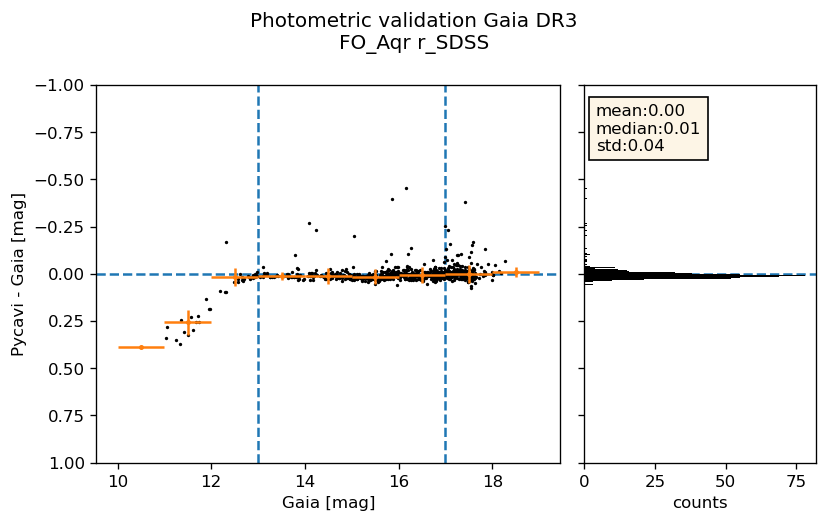

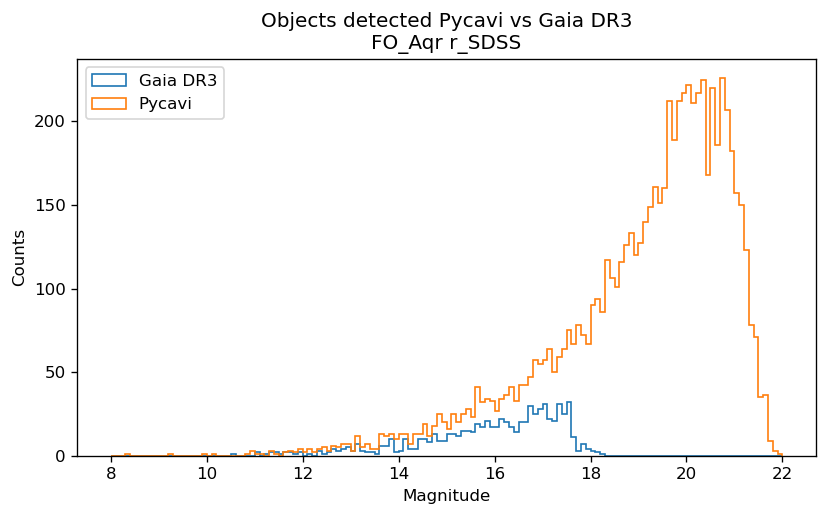

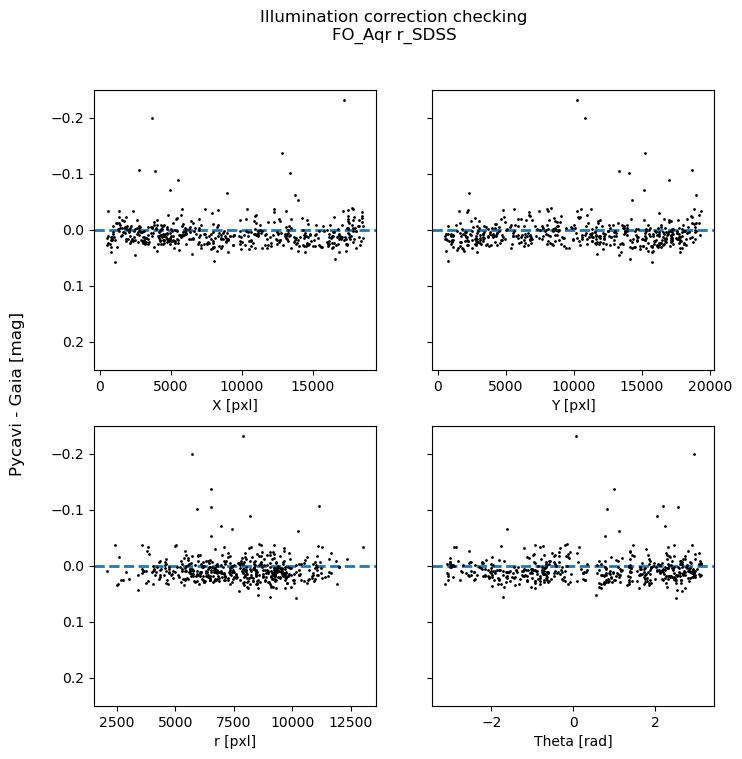

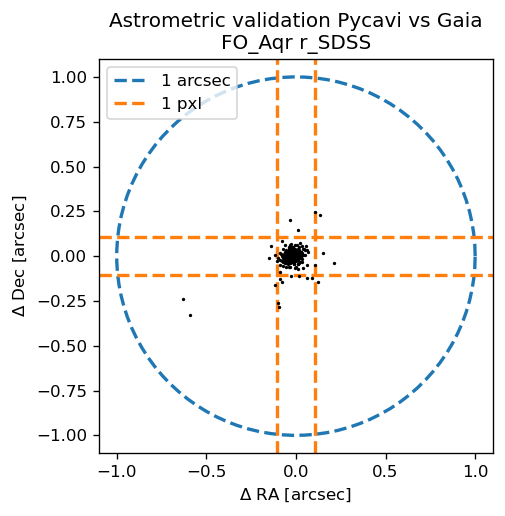

In [7]:
band = 'r_SDSS'
catalogue_idx = [5]
for i in range(len(catalogues)):
    if not i in catalogue_idx:
        continue
    logging.info('Creating check plots over catalogue {}'.format(catalogues[i]))
    create_catalogue_checkplots(catalogues[i], band)